# Ανάλυση της συσχέτισης ηλικίας και φύλου (Age and Gender Distortion Assignment)

Ονοματεπώνυμο Φοιτητή: Ζωή Γιαγλή



## Εισαγωγή 

Σκοπός της εργασίας είναι η εξέταση του φαινομένου της ηλικιακής παραμόρφωσης σε σχέση με το φύλο (age and gender distortion). Τα δεδομένα που χρησιμοποιούνται στην παρούσα ανάλυση ατλούνται από την έρευνα των Douglas Guilbeault, Solène Delecourt και Bhargav Srinivasa Desikan που δημοσιεύτηκε στο περιοδικό Nature. Από την έρευνα τους προκύπτει πως οι γυναίκες τείνουν να παρουσιάζονται νεότερες από τους άντρες, παρά το γεγονός ότι δε παρατηρούνται ουσιαστικές διαφορές ηλικίας μεταξύ των δύο φύλων στον χώρο εργασίας. Αυτή η συστηματική υποεκτίμηση της ηλικίας των γυναικών αποτελεί ένδειξη ύπαρξης ενός έμφυλου στερεοτύπου που ενισχύει την ανισότητα μεταξύ ανδρών και γυναικών. 

Στη παρούσα ανάλυση πραγματοποιείται η αναπαραγωγή των αποτελεσμάτων και η περαιτέρω ανάλυση της σχέσης ηλικίας και φύλου. Πιο συγκεκριμένα διακρίνονται δύο βασικά μέρη:
1. Γλωσσικά Μοντέλα (GPT2-Large): Εξετάζεται η συσχέτιση των αναπαραστάσεων των μεταβλητών ηλικίας και φύλου στο γλωσσικό μοντέλο GPT2-Large. 
2. Πειραματικά Δεδομένα: Ανάλυση πειραματικών δεδομένων, προκειμένου να μελετηθεί η επίδραση της έκθεσης των συμμετεχόντων σε έμφυλες εικόνες στην εκτίμηση της ηλικίας.

Αξιοποιούνται μέθοδοι περιγραφικής στατιστικής, γραμμικά μοντέλα παλινδρόμησης και ανάλυση διακύμανσης ANOVA, ώστε να αξιολογηθεί αν τα συμπεράσματα που προκύπτουν είναι στατιστικά σημαντικά.


#### Εισαγωγή Βιβλιοθηκών

Pandas & NumPy: Για βασική επεξεργασία των πινάκων δεδομένων

Matplotlib, Seaborn & Plotly: Για δημιουργία στατικών και διαδραστικών γραφημάτων

Statsmodels, Scipy & Pingouin: Για στατιστική ανάλυση και ελέγχους υποθέσεων

In [198]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
from matplotlib.patches import Patch
import seaborn as sns
import plotly.graph_objects as go
from IPython.display import display, HTML

from scipy import stats
import pingouin as pg
import statsmodels.api as sm
import statsmodels.formula.api as smf

#### Ορισμός διαδρομών δεδομένων (relative paths):

In [199]:
gpt2 = "data/GPT2-large-dimensions.csv"
experiment_control = "data/experiment_control.csv"
experiment_treatment = "data/experiment_treatment.csv"

## Έλεγχος συσχέτισης ηλικίας και φύλου στο GPT2-Large

Αρχικά, πραγματοποιείται εξέταση του τρόπου που το γλωσσικό μοντέλο GPT2-Large αναπαριστά εσωτερικά τις διαστάσεις του φύλου και της ηλικίας. Αξιοποιείται το αρχείο GPT2-large-dimensions.csv, το οποίο έχει οριστεί ως relative path προηγουμένως, και για κάθε κοινωνική κατηγορία περιλαμβάνει μια αντιστοίχιση σε μια τιμή ως προς τις δύο αυτές διαστάσεις. Σκοπός είναι να διερευνηθεί αν υπάρχει γραμμική συσχέτιση μεταξύ ηλικίας και φύλου, μέσω του υπολογισμού του συντελεστή συσχέτισης Pearson.

In [200]:
gpt_df = pd.read_csv(gpt2)

age = gpt_df["age.main"]
gender = gpt_df["gender.main"]

r, p = stats.pearsonr(age, gender)

pg.corr(age, gender)

,n,r,CI95,p_val,BF10,power
pearson,3495,0.872559,"[0.86, 0.88]",0.0,inf,1.0


Ανάλυση αποτελεσμάτων:
    
n-> Ο αριθμός των παρατηρήσεων στο δείγμα. Στη προκειμένη περίπτωση είναι αρκετά μεγάλος (3495), και άρα τα αποτελέσματα είναι αξιόπιστα.

r-> Ο συντελεστής γραμμικής συσχέτισης, ο οποίος μπορεί να λάβει τιμές από -1 (τέλεια αρνητική γραμμική συσχέτιση) εως +1 (τέλεια θετική γραμμική συσχέτιση), με τη τιμή 0 να σημαίνει πως δεν υπάρχει καμία γραμμική συσχέτιση. Το αποτέλεσμα 0.872559 σημαίνει ότι υπάρχει ισχυρή γραμμική συσχέτιση μεταξύ ηλικίας και φύλου.

CI95-> Το εύρος του διαστήματος εμπιστοσύνης [0.86, 0.88] είναι πολύ μικρό, κάτι που ενισχύει την αξιοπιστία και την ακρίβεια της εκτίμησης του συντελεστή συσχέτισης. 

p_val_> Η στατιστική σημαντικότητα είναι σχεδόν 0 (< 0.05), και άρα μπορούμε να επιβεβαίωσουμε πως η συσχέτιση δεν οφείλεται στη τύχη απορρίπτοντας την μηδενική υπόθεση.

BF10-> Ο δείκτης Bayes Factor είναι infinite, άρα τα δεδομένα παρέχουν εξαιρετικά ισχυρή ένδειξη ύπαρξης συσχέτισης μεταξύ των δύο διαστάσεων που εξετάζουμε.

power-> Η τιμή του συγκεκριμένου δείκτη είναι 1, κάτι που υποδηλώνει ότι η ανάλυση έχει εξαιρετικά υψηλή ικανότητα ανίχνευσης μιας συσχέτισης, αν αυτή υπάρχει.

#### Έλεγχος Ευρωστίας (Robustness Check)

Σε αυτό το σημείο θα υπολογιστούν όλα τα δυνατά ζεύγη συντελεστών συσχέτισης για τις μεταβλητές της ηλικίας και αντίστοιχα για τις μεταβλητές του φύλου και θα οπτικοποιηθούν με μέσo Heatmaps. Αυτό συμβαίνει, ώστε να διασφαλιστεί ότι τα παραπάνω αποτελέσματα δεν επηρεάζονται και εξαρτώνται από τον τρόπο διεξαγωγής των δεδομένων, αλλά παραμένουν σταθερά και με διαφορετικές μεθόδους μέτρησης.

Αρχικά, παίρνουμε από το data frame 'gpt_df' τις τρεις μεταβλητές που σχετίζονται με την ηλικία (age.red, age.ext, age.main) και αντίστοιχα τις τρεις που σχετίζονται με το φύλο (gender.red, gender.ext, gender.main). Δημιουργούμε δύο πίνακες, έναν που να περιέχει τις στήλες για την ηλικία (age_data) και έναν που να περιέχει τις στήλες για το φύλο (gender_data). Αλλάζουμε τα ονομάτα όλων των μεταβλητών, ώστε να περιέχουν κάτω παύλα (_) και όχι τελεία και συνεπώς να είναι πιο εύκολος ο χειρισμός τους και καλύτερη η αναγνωσιμότητά τους. Τέλος, χρησιμοποιούμε τη μέθοδο .corr() για να υπολογιστεί για όλα τα δυνατά ζεύγη των δύο κατηγορίων μεταβλητών (για κάθε κατηγορία ξεχωριστά) ο συντελεστής συσχέτισης Pearson. Τα αποτελέσματα αποθηκεύονται στους πίνακες 'age_corr_matrix' και 'gender_corr_matrix', οι οποίοι θα χρησιμοποιηθούν για τη δημιουργία των Heatmaps.

In [201]:
age_vars = ["age.red", "age.ext", "age.main"]
age_data = gpt_df[age_vars].copy()
age_data.columns = ["age_red", "age_ext", "age_score"]
age_corr_matrix = age_data.corr()

gender_vars = ["gender.red", "gender.ext", "gender.main"]
gender_data = gpt_df[gender_vars].copy()
gender_data.columns = ["gender_red", "gender_ext", "gender_score"]
gender_corr_matrix = gender_data.corr()

Πριν την δημιουργία των Heatmaps, εξετάζουμε το εύρος των τιμών των πινάκων συσχέτισης υπολογίζοντας την ελάχιστη και τη μέγιστη τιμή κάθε πίνακα.  
Στο επόμενο στάδιο, θα αποθηκεύσουμε χειροκίνητα αυτές τις τιμές στις μεταβλητές age_min και gender_min. Αυτό επιτρέπει την καλύτερη προσαρμογή της απεικόνισης στα δεδομένα και καθιστά δυνατή και σαφή τη σύγκριση μεταξύ των δύο διαγραμμάτων.

In [202]:
print(age_corr_matrix.min().min(), age_corr_matrix.max().max())
print(gender_corr_matrix.min().min(), gender_corr_matrix.max().max())

0.5846521973431659 1.0
0.7396911288033376 1.0


Έπειτα, ορίζουμε μια βοηθητική συνάρτηση (red_cmap) που επιστρέφει ένα προσαρμοσμένο τμήμα της χρωματικής παλέτας Reds, ώστε τα χρώματα στο τελικό αποτέλεσμα να έχουν την επιθυμητή ένταση.

Για το διάγραμμα της ηλικίας χρησιμοποιούμε το διάστημα τιμών [0.35, 0.85] της παλέτας. Από την άλλη, για το διάγραμμα του φύλου, υπολογίζουμε αρχικά τη τιμή gender_shift που αντιστοιχεί στη θέση που βρίσκεται η ελάχιστη τιμή του φύλου ενδιάμεσα στην ελάχιστη τιμή ηλικίας και το 1 (μέγιστη κοινή τιμή και για τα δύο διαγράμματα). Έπειτα, υπολογίζουμε τη τιμή gender_start_color που αντιστοιχεί στο σημείο που ξεκινάει η δεύτερη χρωματικά παλέτα, ώστε να υπάρχει συνέπεια χρώματος στα δύο διαγράμματα.

Τέλος δημιουργούμε τα δύο υποδιαγράμματα μαζί, ώστε να παρουσιάζονται το ένα δίπλα στο άλλο και ορίζουμε τις κατάλληλες παραμέτρους για τη βελτίωση της αναγνωσιμότητάς τους.

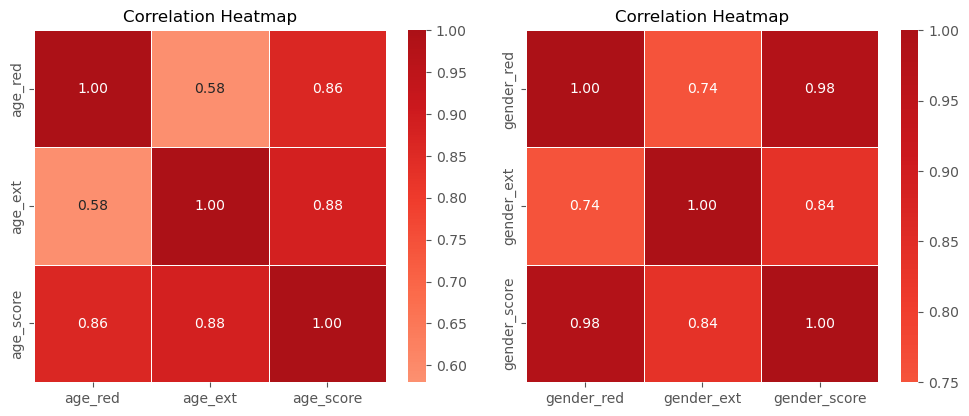

In [203]:
age_min = 0.58
gender_min = 0.74
common_max = 1.0

def red_cmap(cmap_name, start_val, end_val):
    cmap = plt.get_cmap(cmap_name)
    return mcolors.LinearSegmentedColormap.from_list(
        'trunc_cmap', cmap(np.linspace(start_val, end_val, 256))
    )


age_cmap = red_cmap("Reds", 0.38, 0.85)

gender_shift = (gender_min - age_min) / (common_max - age_min)
gender_start_color = 0.38 + gender_shift * (0.85 - 0.38)
gender_cmap = red_cmap("Reds", gender_start_color, 0.85)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(age_corr_matrix, annot=True, fmt=".2f", cmap=age_cmap, vmin=age_min, vmax=common_max, square=True, linewidths=0.5, ax=ax[0],
            cbar_kws={"ticks": np.arange(0.60, 1.01, 0.05)})
ax[0].set_title("Correlation Heatmap", fontsize=12)

sns.heatmap(gender_corr_matrix, annot=True, fmt=".2f", cmap=gender_cmap, vmin=0.75, vmax=common_max, square=True, linewidths=0.5, ax=ax[1],
            cbar_kws={"ticks": np.arange(0.75, 1.01, 0.05)})
ax[1].set_title("Correlation Heatmap", fontsize=12)

plt.tight_layout()
plt.show()

Τα δύο Heatmaps επιβεβαιώνουν την ευρωστία των δεδομένων και ότι τα αποτελέσματα των μεταβλητών ηλικίας και φύλου στο γλωσσικό μοντέλο GPT2-Large δεν εξαρτώνται από τον τρόπο εξαγωγής των μεταβλητών. Πιο συγκεκριμένα, φαίνεται πως οι διαφορετικές μέθοδοι μέτρησης (red, ext, main) συσχετίζονται μεταξύ τους. Στο διάγραμμα της ηλικίας, οι συσχετίσεις κυμαίνονται από τιμές 0.58 έως 0.88, ενώ στο διάγραμμα του φύλου υπάρχουν ακόμα πιο ισχυρές συσχετίσεις, με τιμές από 0.74 έως 0.98, κάτι που επιβεβαιώνεται και οπτικά από τα εντονότερα χρώματα.

## Σχέση ηλικίας και φύλου

Τώρα θα εξεταστεί η σχέση μεταξύ των διαστάσεων της ηλικίας και του φύλου, χρησιμοποιώντας ένα μοντέλο γραμμικής παλινδρόμησης (OLS regression model). Στο μοντέλο αυτό η εξαρτημένη μεταβλητή είναι η κανονικοποιημένη διάσταση της ηλικία και η ανεξάρτητη είναι η κανονικοποιημένη διάσταση του φύλου. Τα αποτελέσματα θα φανερώσουν αν η σχέση του φύλου και της ηλικίας είναι στατιστικά σημαντική

#### OLS regression model


Αρχικά, ορίζεται το μοντέλο, όπου η μεταβλητή της ηλικίας υπολογίζεται με βάση τη μεταβλητή του φύλου. Χρησιμοποιείται η συνάρτηση Q() για να μπορούν να διαβαστούν σωστά τα ονόματα των στηλών μέσα στο μοντέλο, καθώς αυτά περιέχουν τελείες. Στη συνέχεια, χρησιμοποιούμε HTML ώστε ο πίνακας να εμφανιστεί κεντραρισμένος και τέλος, εκτυπώνουμε τα αποτελέσματα.

In [204]:
model = smf.ols("Q('age_norm.main') ~ Q('gender_norm.main')", data=gpt_df).fit()

display(HTML("""
<style>
    table.simpletable {
        margin-left: auto !important;
        margin-right: auto !important;
    }
</style>
"""))

model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     Q('age_norm.main')   R-squared:                       0.761
Model:                            OLS   Adj. R-squared:                  0.761
Method:                 Least Squares   F-statistic:                 1.114e+04
Date:                Sat, 25 Apr 2026   Prob (F-statistic):               0.00
Time:                        16:57:07   Log-Likelihood:                 5425.6
No. Observations:                3495   AIC:                        -1.085e+04
Df Residuals:                    3493   BIC:                        -1.083e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.0211      0.003     -6.510      0.000      -0.027      -0.015
Q('gender_norm.main')     0.7450      0.007    105.565      0.000       0.731       0.759
==============================================================================
Omnibus:                      829.901   Durbin-Watson:                   1.255
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4643.267
Skew:                           1.012   Prob(JB):                         0.00
Kurtosis:                       8.271   Cond. No.                         9.75
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Ερμηνεία αποτελεσμάτων παλινδρόμησης:

R² -> Το φύλο εξηγεί το 76.1% της διακύμανσης της ηλικίας. Αυτό το ποσοστό είναι ιδιαίτερα υψηλό, κάτι που σημαίνει πως οι δύο αυτές διαστάσεις έχουν μεγάλη συσχέτιση στο γλωσσικό μοντέλο GPT2-Large.

coef - gender_norm.main -> Ο συντελεστής είναι θετικός, και άρα για κάθε μονάδα που αυξάνεται το φύλο, αυξάνεται κατά 0.745 μονάδες και η ηλικία. 

p-value -> Η τιμή είναι σχεδόν μηδενική και γι το Intercept, αλλά και για τον συντελεστή gender_norm.main και άρα η σχέση φύλου - ηλικίας είναι στατιστικά σημαντική.

Confidence Interval-> Το 95% διάστημα εμπιστοσύνης για τον συντελεστή του gender_norm.main είναι [0.731, 0.759]. Καθώς είναι στενό και δεν περιλαμβάνει το μηδέν ενισχύεται η αξιοπιστία της εκτίμησης.

F-statistic -> Η τιμή 1.114e+04 (με p-value = 0.00) υποδηλώνει πως το μοντέλο συνολικά είναι στατιστικά σημαντικό.

Skewness -> Η τιμή 1.012 σημαίνει ότι τα κατάλοιπα του μοντέλου δεν είναι συμμετρικά κατανεμημένα, αλλά παρουσιάζουν δεξιά ασυμμετρία.

Kurtosis -> Η τιμή 8.271 είναι πολύ υψηλή και υποδηλώνει την ύπαρξη ακραίων τιμών.

Jarque–Bera -> Η υψηλή τιμή του δείκτη (4643.267) και το p-value = 0 επιβεβαιώνουν επίσης ότι τα κατάλοιπα δεν ακολουθούν κανονική κατανομή.

Τα αποτελέσματα της παλινδρόμησης δείχνουν ότι το φύλο αποτελεί σημαντικό προβλεπτή της ηλικίας στο γλωσσικό μοντέλο GPT2-Large. Παρ' όλα αυτά, τα διαγνωστικά ελέγχου (Skewness, Kurtosis, Jarque-Bera) δείχνουν πως υπάρχουν παραβιάσεις της υπόθεσης κανονικότητας των καταλοίπων, και άρα τα αποτελέσματα πρέπει να ερμηνεύονται με επιφύλαξη.

## Οπτικοποίηση της σχέσης ηλικίας - φύλου (Regression plot)

Σε αυτό το σημείο παρουσιάζεται η σχέση μεταξύ της ηλικίας και του φύλου με ένα διάγραμμα παλινδρόμησης. Για να γίνει το διάγραμμα πιο κατανοητό, έχουν επιλεχθεί ορισμένες αντιπροσωπευτικές κατηγορίες που επισημάνονται με χρώμα. Πιο συγκεκριμένα, με μπλε χρώμα εμφανίζονται ρόλοι που σχετίζονται με το ανδρικό φύλο και με μεγαλύτερες ηλικίες, ενώ με πορτοκαλί χρώμα αυτοί που σχετίζονται με το γυναικείο φύλο και μικρότερες ηλικίες.

Αρχικά φορτώνονται τα δεδομένα και γίνεται ο ορισμός των επιλεγμένων κατηγοριών. Τα δεδομένα χωρίζονται σε αυτά που θα επισημανθούν με χρώμα και ετικέτες και σε αυτά που αποτελούν το φόντο του διαγράμματος. Τα επιλεγμένα δεδομένα χωρίζονται περαιτέρω σε δύο κατηγορίες ανάλογα με τον πόλο του φύλου που αντιπροσωπεύουν, ώστε να τους αποδοθούν διαφορετικά χρώματα.

In [205]:
plot_df = pd.read_csv(gpt2)

highlight_categories = [
    "chairman of the board", "elected official", "military personnel", "director of research", "chief of staff","homoeopath", "intern", "cook", 
    "secretary", "novice"
]

highlight_df = plot_df[plot_df["Social.Category"].isin(highlight_categories)]
base_df = plot_df[~plot_df["Social.Category"].isin(highlight_categories)]

side1 = [
    "chairman of the board", "elected official",
    "military personnel", "director of research", "chief of staff"
]
side2 = [
    "homoeopath", "intern", "cook", "secretary", "novice"
]

Έπειτα, δημιουργείται το διάγραμμα διασποράς, χρησιμοποιώντας το στυλ 'ggplot'. Σχεδιάζονται τα σημεία των δεδομένων που θα εμφανιστούν στο φόντο, η ευθεία της παλινδρόμησης που εμφανίζει τη γραμμική σχέση μεταξύ ηλικίας και φύλου και τα επιλεγμένα (highlighted) δεδομένα.

In [206]:
plt.style.use("ggplot")
fig, ax = plt.subplots(figsize=(6.5, 5.8))

ax.scatter(base_df["gender_norm.main"], base_df["age_norm.main"], 
           s=14, facecolors="none", edgecolors="black", linewidths=0.9, alpha=0.9, zorder=1)
coef = np.polyfit(plot_df["gender_norm.main"], plot_df["age_norm.main"], 1)
x_line = np.linspace(plot_df["gender_norm.main"].min() - 0.05, plot_df["gender_norm.main"].max() + 0.05, 200)
y_line = coef[0] * x_line + coef[1]

ax.plot(x_line, y_line, color="red", linewidth=1.2, zorder=2)

right_df = highlight_df[highlight_df["Social.Category"].isin(side1)]
left_df  = highlight_df[highlight_df["Social.Category"].isin(side2)]

ax.scatter(right_df["gender_norm.main"], right_df["age_norm.main"],
           s=55, color="dodgerblue", edgecolors="black", linewidths=0.8, zorder=3)
ax.scatter(left_df["gender_norm.main"], left_df["age_norm.main"],
           s=55, color="orange", edgecolors="black", linewidths=0.8, zorder=3)

plt.close(fig)

Ορίζονται χειροκίνητα οι ετικέτες των επιλεγμένων κατηγοριών, ώστε το διάγραμμα να είναι ευανάγνωστο.

In [207]:
labels = {
    "chairman of the board": (-52, 55),
    "elected official":      (-52, 25),
    "military personnel":    (-150, 30),
    "director of research":  (12, -28),
    "chief of staff":        (8, -18),
    "homoeopath":            (-75, 12),
    "intern":                (-32, 10),
    "cook":                  (-15, -28),
    "secretary":             (-5, -24),
    "novice":                (25, -8),
}

Τέλος, προστίθονται οι ετικέτες στις επιλεγμένες κατηγορίες, οι τίτλοι των αξόνων και τα όρια και το πλέγμα του διαγράμματος. 

<Figure size 640x480 with 0 Axes>

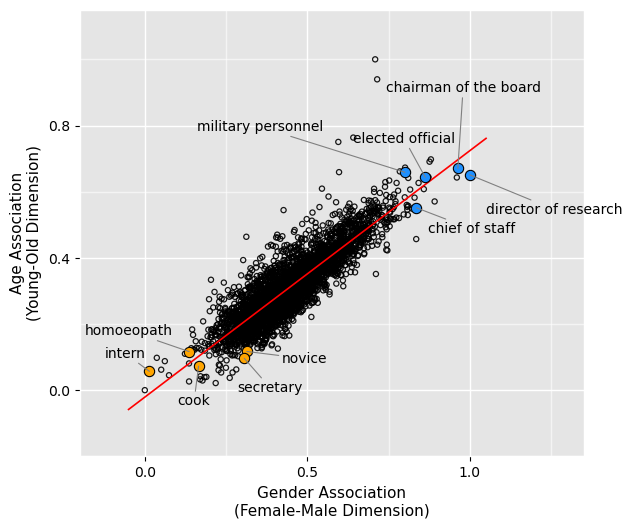

In [208]:

for _, row in highlight_df.iterrows():
    label = row["Social.Category"]
    dx, dy = labels[label]
    ax.annotate(
        label,
        xy=(row["gender_norm.main"], row["age_norm.main"]),
        xytext=(dx, dy), textcoords="offset points",
        fontsize=10, color="black",
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, shrinkA=0, shrinkB=0),
        zorder=4
    )

ax.set_xlabel("Gender Association\n(Female-Male Dimension)", fontsize=11, color="black")
ax.set_ylabel("Age Association\n(Young-Old Dimension)", fontsize=11, color="black")

ax.set_xlim(-0.2, 1.35)
ax.set_ylim(-0.2, 1.15)
ax.set_xticks([0.0, 0.5, 1.0])
ax.set_yticks([0.0, 0.4, 0.8])

ax.xaxis.set_minor_locator(MultipleLocator(0.25))
ax.yaxis.set_minor_locator(MultipleLocator(0.2))

ax.grid(True, which="major", color="white", linewidth=1.0)
ax.grid(True, which="minor", color="white", linewidth=1.0, alpha=0.6)
ax.tick_params(axis="both", which="major", labelsize=10, colors="black")
ax.tick_params(axis="both", which="minor", length=0)

plt.tight_layout()
plt.show()
fig

## Διαδραστικό διάγραμμα (Interactive regression plot)

Στη συνέχεια, δημιουργούμε μια διαδραστική εκδοχή του παραπάνω διαγράμματος. Σε αυτή την εκδοχή, εμφανίζονται λεπτομέρειες για όλες τις κατηγορίες ώστε ο αναγνώστης να μπορεί να τις εξετάσει όλες. 


Αρχικά, φορτώνονται τα δεδομένα και ορίζονται οι κατηγορίες που θα αναδειχθούν. Έπειτα, ανθέτονται χρώματα σε κάθε σημείο ανάλογα με τη θέση του στο διάγραμμα. Τα κάτω αριστερά σημεία χρωματίζονται πορτοκαλί, τα πάνω δεξία μπλε, ενώ τα υπόλοιπα παραμένουν γκρι ώστε να ξεχωρίζουν οι επιλεγμένες κατηγορίες. Για να είναι ακόμα πιο ευδιάκριτα τα επιλεγμένα σημεία, ορίζεται ανάλογα το μέγεθός τους.

In [209]:
plot_df = pd.read_csv(gpt2)

highlights = [
    "chairman of the board", "elected official", "military personnel", "director of research", "chief of staff",
    "homoeopath", "intern", "cook", "secretary", "novice"
]

right = [
    "chairman of the board", "elected official", "military personnel", "director of research", "chief of staff"
]

left = [
    "homoeopath", "intern", "cook", "secretary", "novice"
]

plot_df["color"] = "#bdbdbd"

plot_df.loc[plot_df["Social.Category"].isin(right), "color"] = "dodgerblue"
plot_df.loc[plot_df["Social.Category"].isin(left), "color"] = "orange"
plot_df["size"] = 7
plot_df.loc[plot_df["Social.Category"].isin(highlights), "size"] = 13

Υπολογίζεται η ευθεία παλινδρόμησης που θα ενσωματωθεί στο γράφημα, χρησιμοποιώντας της κανονικοποιημένες μεταβλητές ηλικίας και φύλου και εφαρμόζοντας τη μέθοδο ελαχίστων τετραγώνων.

In [210]:
x = plot_df["gender_norm.main"]
y = plot_df["age_norm.main"]

b1, b0 = np.polyfit(x, y, 1)

x_line = np.linspace(x.min() - 0.05, x.max() + 0.05, 300)
y_line = b1 * x_line + b0

Τέλος, δημιουργείται με τη βιβλιοθήκη Plotly το διαδραστικό διάγραμμα. Μέσω της παραμέτρου 'hovertemplate' για κάθε σημείο εμφανίζεται ένα πλαίσιο με το όνομα της κατηγορίας, την τιμή του φύλου και της ηλικίας όταν ο χρήστης τοποθετεί το ποντίκι πάνω του. Προστίθεται και η ευθεία της παλινδρόμησης με κόκκινο χρώμα για να είναι δυνατή η οπτική ερμηνεία των αποτελεσμάτων. Σε αυτό το σημείο, ρυθμίζεται και η εμφάνιση των αξόνων καθώς και η γενική αισθητική του γραφήματος.


In [211]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=x,
        y=y,
        mode="markers",
        marker=dict(
            size=plot_df["size"],
            color=plot_df["color"],
            line=dict(color="rgba(80,80,80,0.7)", width=0.8),
            opacity=0.75
        ),
        customdata=np.stack([
            plot_df["Social.Category"],
            x,
            y
        ], axis=-1),
        hovertemplate=(
            "category: %{customdata[0]}<br>"
            "gender: %{customdata[1]:.2f}<br>"
            "age: %{customdata[2]:.2f}"
            "<extra></extra>"
        ),
        showlegend=False
    )
)

fig.add_trace(
    go.Scatter(
        x=x_line,
        y=y_line,
        mode="lines",
        line=dict(color="red", width=3),
        hoverinfo="skip",
        showlegend=False
    )
)

fig.update_layout(
    width=650,
    height=650,
    plot_bgcolor="white",
    paper_bgcolor="white",
    margin=dict(l=70, r=40, t=30, b=70),
    xaxis=dict(
        title="Gender Association<br>(Female-Male Dimension)",
        range=[-0.02, 1.02],
        tickvals=np.arange(0.0, 1.01, 0.1),
        showgrid=True,
        gridcolor="#d0d0d0"
    ),
    yaxis=dict(
        title="Age Association<br>(Young-Old Dimension)",
        range=[0.0, 1.0],
        tickvals=np.arange(0.0, 1.01, 0.1),
        showgrid=True,
        gridcolor="#d0d0d0"
    ),
    font=dict(color="black", size=16)
)

fig.show()


Για να εξετάσουμε ποιες ακραίες παρατηρήσεις (outliers) δεν έχουν επιλεχθεί ως αναδειγμένες (highlighted) από τους συγγραφείς θα υπολογίσουμε τα κατάλοιπα της παλινδρόμησης. Αρχικά, στη στήλη 'predicted_age' υπολογίζεται για κάθε κοινωνική κατηγορία η προβλεπόμενη τιμή της ηλικίας με βάση την τιμή του φύλου. Έπειτα, υπολογίζεται το κατάλοιπο (residual), σύμφωνα με τη διαφορά της πραγματικής τιμής της ηλικίας και της προβλεπόμενης. Για να βρεθούν τα σημεία που δεν έχουν επιλέξει οι συγγραφείς, παραβλέπονται οι κατηγορίες που έχουν ήδη επισημανθεί στο γράφημα. Τέλος, από κάθε ομάδα καταλύπων (πάνω από τη γραμμή παλινδρόμησης/ κάτω από τη γραμμή παλινδρόμησης) επιλέγονται οι δέκα μεγαλύτερες τιμές, ώστε να εξετάσουμε τις πιο ακραίες και σημαντικές τιμές. 


In [212]:
plot_df["predicted_age"] = b0 + b1 * plot_df["gender_norm.main"]
plot_df["residual"] = plot_df["age_norm.main"] - plot_df["predicted_age"]

non_highlighted = plot_df[~plot_df["Social.Category"].isin(highlights)]

outliers_a = (non_highlighted[non_highlighted["residual"] > 0]
                  .nlargest(10, "residual"))

outliers_b = (non_highlighted[non_highlighted["residual"] < 0]
                  .nsmallest(10, "residual"))

print("Πάνω από τη γραμμή παλινδρόμησης:")
print(outliers_a[["Social.Category", "gender_norm.main", "age_norm.main", "residual"]].to_string())

print("\nΚάτω από τη γραμμή παλινδρόμησης:")
print(outliers_b[["Social.Category", "gender_norm.main", "age_norm.main", "residual"]].to_string())

Πάνω από τη γραμμή παλινδρόμησης:
      Social.Category  gender_norm.main  age_norm.main  residual
416    brother-in-law          0.708811       1.000000  0.493047
1320    father-in-law          0.714942       0.939619  0.428099
934   daughter-in-law          0.595438       0.750369  0.327875
3125    sister-in-law          0.641499       0.763524  0.306716
2540          non-jew          0.312368       0.463658  0.252041
2430    mother-in-law          0.426903       0.544268  0.247326
2024      know-it-all          0.597693       0.658999  0.234825
2218      man-at-arms          0.545072       0.609150  0.224176
1048       dispatcher          0.203601       0.333655  0.203064
2895        pro-lifer          0.302694       0.393186  0.188775

Κάτω από τη γραμμή παλινδρόμησης:
          Social.Category  gender_norm.main  age_norm.main  residual
1649       great grandson          0.409492       0.125626 -0.158346
1035             director          0.711153       0.351134 -0.157563
2241     

Τα παραπάνω αποτελέσματα αποκαλύπτουν ποιες αποκλίνουσες κατηγορίες έχουν επιλέξει οι συγγραφείς της έρευνας να μην επισημάνουν. Τα κατάλοιπα πάνω από τη γραμμή παλινδρόμησης σχετίζονται κυρίως με οικογενειακές σχέσεις (in-laws), καθώς και με περιγραφικούς χαρακτηρισμούς (know-it-all). Παρομοίως, τα κατάλοιπα κάτω απο τη γραμμή παλινδρόμησης σχετίζονται πάλι με συγγενικές σχέσεις (great grandson, granddaughter), καθώς και με κάποια καλλιτεχνικά επαγγέλματα (director, author). Αυτές οι κατηγορίες μπορεί να έχουν την μεγαλύτερη απόκλιση από τη γραμμή παλινδρόμησης, αλλά δεν υπάρχει κάποια κοινωνική και σημασιολογική ερμηνευσιμότητα των αποτελεσμάτων που χρήζει περαιτέρω διερεύνηση. Αντίθετα, οι επιλεγμένες, από τους συγγραφείς, κατηγορίες του διαγράμματος φαίνεται να αποτελούν επαγγέλματα τα οποία είναι στενά συνδεδεμένα με κοινωνικά και ηλικιακά στερεότυπα.Πιο συγκεκριμένα, με πορτοκαλί χρώμα έχουν χρωματιστεί κατηγορίες που παραδοσιακά συνδέονται με γυναίκες και νεότερες ηλικίες, όπως γραμματέας (secretary), μάγειρας/ μαγείρισσα (cook) και ασκούμενος/η (intern). Από την άλλη, με μπλε χρώμα έχουν χρωματιστεί ρόλοι υψηλού κύρους και εξουσίας που στερεοτυπικά συνδέονται με άντρες και μεγαλύτερες ηλικίες, όπως ο πρόεδρος διοικητικού συμβουλίου (chairman of the board) και ο αρχηγός επιτελείου (chief of staff). Έτσι αναδεικνύεται η μεροληψία του γλωσσικού μοντέλου, μέσω της συστηματικής αντιστοίχισης ρόλων με έμφυλα και ηλικιακά στερεότυπα.

## Ενίσχυση της μεροληψίας από την αναζήτηση στο Google (Amplification via Google Search)

Παρακάτω εξετάζεται κατά πόσο τα αποτελέσματα διαδικτυακής αναζήτησης εικόνων στο Google ενισχύουν τις παρατηρούμενες στρεβλώσεις ηλικίας - φύλου. Θα χρησιμοποιηθούν δεδομένα από το πείραμα των συγγραφών της έρευνας. Πιο συγκεκριμένα, το πείραμα συμπεριλάμβανε τον διαχωρισμό των συμμετεχόντων σε δύο ομάδες. Η πρώτη ομάδα, η ομάδα ελέγχου (control condition), χρησιμοποιήσε το Google Images για να αναζητήσει εικόνες άσχετων κατηγοριών, όπως ένα μήλο, και έπειτα κλήθηκε να εκτιμήσει την μέση ηλικία κάποιου που ασκεί ένα συγκεκριμένο επάγγελμα. Από την άλλη, η ομάδα παρέμβασης (treatment condition) χρησιμοποιήσε το Google Images για να αναζητήσει εικόνες επαγγελμάτων και έπειτα κλήθηκε να ονομάσει το φύλο του ατόμου που απεικονίζεται και να εκτιμήσει την μέση ηλικία των ατόμων που ασκούν αυτό το επάγγελμα. Ο στόχος της ανάλυσης των αποτελεσμάτων του πειράματος, είναι να ερευνηθεί αν η έκθεση σε μια εικόνα που περιέχει το φύλο του εργαζομένου, επηρεάζει την αντίληψη για την ηλικία του από τον χρήστη.


Αρχικά, φορτώνονται τα δεδομένα για τις δύο ομάδες από τα αρχεία του πειράματος. Υπολογίζεται η μέση ηλικία που έχει εκτιμηθεί για κάθε κατηγορία επαγγέλματος από την ομάδα ελέχγου. Έπειτα συγχωνεύονται τα δεδομένα της ομάδας παρέμβασης, με την μέση ηλικία της ομάδας ελέγχου που έχει υπολογιστεί πριν (age_c). Στην μεταβλητή 'age_diff' αποθηκεύεται η διαφορά της εκτιμώμενης ηλικίας της ομάδας παρέμβασης με την μέση τιμή της ομάδας ελέγχου για κάθε κατηγορία. Οι παρατηρήσεις χωρίζονται ανάλογα με το φύλο που απεικονιζόταν σε κάθε εικόνα που ανέβασαν οι συμμετέχοντες (male/ female), ώστε να είναι δυνατή η σύγκριση των εκτιμήσεων ηλικίας με βάση το φύλο.

In [213]:
df_c = pd.read_csv(experiment_control)
df_t = pd.read_csv(experiment_treatment)

age_c = (
    df_c
    .groupby("category")["age"]
    .mean()
    .reset_index()
    .rename(columns={"age": "age_c"})
)

df_e = df_t.merge(age_c, on="category", how="left")
df_e["age_diff"] = df_e["age"] - df_e["age_c"]

male = df_e[df_e["gender"] == "Male"] 
female = df_e[df_e["gender"] == "Female"]

Στη συνέχεια, κατασκευάζεται το διάγραμμα πυκνότητας για να γίνει εμφανής η διαφορά στην αντίληψη της ηλικίας με οπτικό τρόπο. Στο διάγραμμα παρουσιάζονται οι εκτιμήσεις των ανδρικών και των γυναικείων εικόνων, σε σχέση με την ομάδα ελέγχου που παίρνει τη τιμή 0 στον άξονα x. Χρησιμοποιούνται καμπύλες πυκνότητας για τις δύο ομάδες για να αποτυπωθεί η μορφή της κατανομής της 'age_diff'. Επίσης, προστίθονται μαύρα περιγράμματα στις δύο καμπύλες για καλύτερη αναγνωσιμότητα και κατακόρυφες γραμμές που αντιστοιχούν στον μέσο όρο κάθε ομάδας επιτρέποντας τη σύγκριση των δύο ομάδων ως προς τη μέση απόκλιση ηλικίας από την ομάδα ελέγχου. Πιο συγκεκριμένα, η μαύρη διακεκομμένη γραμμή στη θέση 0 λειτουργεί ως σημείο αναφοράς για την ομάδα ελέγχου. Η οπτικοποίηση αυτή είναι χρήσιμη, καθώς καθιστά εμφανές το γεγονός ότι οι συμμετέχοντες που ανέβασαν γυναικεία εικόνα τείνουν να εκτιμούν τις ηλικίες χαμηλότερα από την ομάδα ελέγχου, ενώ όσοι ανέβασαν ανδρική εικόνα τείνουν να δίνουν υψηλότερες ηλικιακές εκτιμήσεις. Οπότε το διάγραμμα υποδεικνύει ότι η οπτική έκθεση σε εικόνες από την αναζήτηση Google Images ενισχύει την ηλικιακή παραμόρφωση σε σχέση με το φύλο.

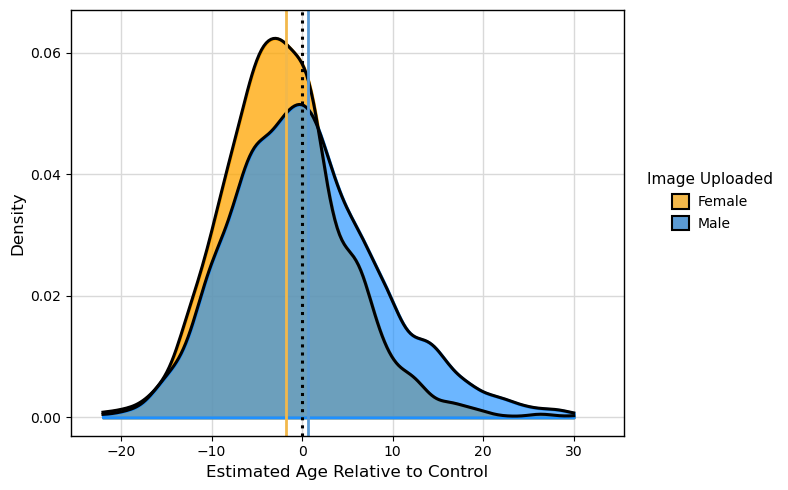

In [214]:
plt.style.use("ggplot")

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

sns.kdeplot(
    female["age_diff"],
    fill=True, color="orange", alpha=0.75, linewidth=2.2, ax=ax,
    cut=0, bw_adjust=0.75, clip=(-22, 30)
)

sns.kdeplot(
    male["age_diff"],
    fill=True, color="dodgerblue", alpha=0.65, linewidth=2.2, ax=ax,
    cut=0, bw_adjust=0.75, clip=(-22, 30)
)

sns.kdeplot(female["age_diff"], color="black", linewidth=2.2, ax=ax, cut=0, clip=(-22, 30), bw_adjust=0.75)
sns.kdeplot(male["age_diff"],   color="black", linewidth=2.2, ax=ax, cut=0, clip=(-22, 30), bw_adjust=0.75)

f_mean = female["age_diff"].mean()
m_mean = male["age_diff"].mean()

ax.axvline(f_mean, color="#f2b84b", linewidth=2)
ax.axvline(m_mean, color="#5b9bd5", linewidth=2)
ax.axvline(0, color="black", linestyle=":", linewidth=2.2)

ax.set_xlabel("Estimated Age Relative to Control", fontsize=12, color="black")
ax.set_ylabel("Density", fontsize=12, color="black")
ax.set_xlim(-25.5, 35.5)
ax.set_ylim(-0.003, 0.067)

ax.set_xticks([-20, -10, 0, 10, 20, 30])
ax.set_yticks([0.00, 0.02, 0.04, 0.06])

ax.minorticks_off()
ax.grid(True, which="major", color="#d9d9d9", linewidth=1.0)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.0)

handles = [
    Patch(facecolor="#f2b84b", edgecolor="black", linewidth=1.5, label="Female"),
    Patch(facecolor="#5b9bd5", edgecolor="black", linewidth=1.5, label="Male"),
]

leg = ax.legend(
    handles=handles,
    title="Image Uploaded",
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.02, 0.55),
    handlelength=1.2,
    handleheight=1.2,
    handletextpad=0.6
)

plt.setp(leg.get_title(), fontsize=11, color="black")
for txt in leg.get_texts():
    txt.set_color("black")
    txt.set_fontsize(10)

ax.tick_params(axis="both", labelsize=10, colors="black")

plt.tight_layout()
plt.show()

#### T-tests

Για να παράξουμε τα ίδια αποτελέσματα με τους συγγραφείς της έρευνας περιορίζουμε αρχικά το δείγμα μόνο στις παρατηρήσεις για τις οποίες το φύλο της εικόνας έχει καταγραφεί ως Female ή Male, ώστε να είναι δυνατή η άμεση σύγκριση μεταξύ των δύο ομάδων. Στη συνέχεια, χωρίζουμε τα δεδομένων σε δύο υποσύνολα, ένα για τις ανδρικές εικόνες (m) και ένα για τις γυναικείες εικόνες (f). Υπολογίζουμε τους μέσους όρους της μεταβλητής 'age' για τις δύο ομάδες, καθώς και τους μέσους όρους της μεταβλητής ΄'age_diff', η οποία εκφράζει την απόκλιση της εκτίμησης ηλικίας από τη μέση τιμή της ομάδας ελέγχου για την ίδια κατηγορία. Με βάση αυτές τις τιμές, υπολογίζουμε τις αντίστοιχες διαφορές μέσων όρων. Έπειτα εφαρμόζουμε τους κατάλληλους στατιστικούς ελέγχους. Για τη σύγκριση μεταξύ γυναικείων και ανδρικών εικόνων χρησιμοποιούμε t-test ανεξάρτητων δειγμάτων πάνω στην αρχική μεταβλητή 'age',χωρίς την υπόθεση ίσων διακυμάνσεων, καθώς θέλουμε να συγκρίνουμε απευθείας τις εκτιμήσεις ηλικίας μεταξύ των δύο ομάδων του treatment (γυναικείες και ανδρικές εικόνες). Για τις συγκρίσεις με την ομάδα ελέγχου χρησιμοποιούμε one-sample t-tests πάνω στη μεταβλητή 'age_diff', επειδή θέλουμε να εξετάσουμε κατά πόσο οι εκτιμήσεις κάθε ομάδας διαφέρουν από την τιμή αναφοράς της ομάδας ελέγχου. Τέλος, εμφανίζουμε για κάθε σύγκριση τη διαφορά ηλικίας, την τιμή του t-statistic και το αντίστοιχο p-value, ώστε να αξιολογήσουμε τόσο την κατεύθυνση όσο και τη στατιστική σημαντικότητα των διαφορών.


In [215]:
df_fm = df_e[df_e["gender"].isin(["Female", "Male"])]
m = df_fm[df_fm["gender"] == "Male"]
f = df_fm[df_fm["gender"] == "Female"]

m_age = m["age"].mean()
f_age = f["age"].mean()
f_diff = f["age_diff"].mean()
m_diff = m["age_diff"].mean()

t_fm, p_fm = stats.ttest_ind(f["age"], m["age"], equal_var=False)
t_f, p_f = stats.ttest_1samp(f["age_diff"], 0)
t_m, p_m = stats.ttest_1samp(m["age_diff"], 0)

diff_fm = f_age - m_age
diff_f = f_diff
diff_m = m_diff

print("Female vs Male:")
print("Age difference:", round(diff_fm, 2))
print("t =", round(t_fm, 2), ", p =", f"{p_fm:.2e}")

print("\nFemale vs Control:")
print("Age difference:", round(diff_f, 2))
print("t =", round(t_f, 2), ", p =", f"{p_f:.2e}")

print("\nMale vs Control:")
print("Age difference:", round(diff_m, 2))
print("t =", round(t_m, 2), ", p =", f"{p_m:.2e}")

Female vs Male:
Age difference: -5.46
t = -19.07 , p = 5.24e-78

Female vs Control:
Age difference: -1.75
t = -11.32 , p = 4.82e-29

Male vs Control:
Age difference: 0.64
t = 3.42 , p = 6.37e-04


Τα παραπάνω αποτελέσματα δείχνουν ότι οι συμμετέχοντες που ανέβασαν γυναικεία εικόνα εκτίμησαν την ηλικία ως σημαντικά χαμηλότερη σε σχέση με όσους ανέβασαν ανδρική εικόνα (-5.46 χρόνια). Επιπλέον, οι εικόνες με γυναίκες οδηγούν σε χαμηλότερες εκτιμήσεις ηλικίας και σε σύγκριση με την ομάδα ελέγχου (-1.75), ενώ οι ανδρικές εικόνες σε υψηλότερες (0.64). Άρα η έκθεση σε εικόνες φαίνεται να ενισχύει τη σύνδεση των γυναικών με μικρότερες ηλικίες και των ανδρών με μεγαλύτερες.

## Διερεύνηση της ενίσχυσης της στρέβλωσης (Investigation of the Amplification)

Για να διερευνηθεί περαιτέρω η ενίσχυση της στρέβλωσης, θα πραγματοποιηθεί η ένωση της ομάδας ελέγχου (control) και της ομάδας παρέμβασης (treatment) σε ένα κοινό σύνολο δεδομένων. Θα εκτελεστεί έπειτα παλινδρόμηση με εξαρτημένη μεταβλητή την ηλικία (age) και ανεξάρτητες την αλληλεπίδραση μεταξύ condition και gender (με χρήση Treatment coding και επίπεδα αναφοράς τη κατηγορία Control για τη μεταβλητή 'condition' και τη κατηγορία Male για τη μεταβλητή 'gender'), την κατηγορία επαγγέλματος (category), και τον συμμετέχοντα (subj). 

Αρχικά, φορτώνονται τα δεδομένα από τις δύο ομάδες. Προστίθεται χειροκίνητα η μεταβλητή 'condition', ώστε να είναι δυνατός ο διαχωρισμός των παρατηρήσεων σε 'control' και 'image' όταν οι δύο ομάδες ενωθούν. Έπειτα, ενώνονται τα δεδομένα σε ένα ενιαίο σύνολο και εξαιρούνται οι παρατηρήσεις για τις οποίες το φύλο δεν είναι 'άνδρας' ή 'γυναίκα'. 

In [216]:
df_c = pd.read_csv(experiment_control)
df_t = pd.read_csv(experiment_treatment)
df_c["condition"] = "Control"
df_t["condition"] = "Image"

df_together = pd.concat([df_c, df_t], ignore_index=True)
df_together = df_together[df_together["gender"].isin(["Female", "Male"])].copy()

Στη συνέχεια δημιουργείται το μοντέλο της γραμμικής παλινδρόμησης. Ως εξαρτημένη μεταβλητή χρησιμοποιείται η ηλικία που έχει εκτιμηθεί από τον συμμετέχοντα. Ως ανεξάρτητη μεταβλητή χρησιμοποιείται η αλληλεπίδραση 'condition * gender', καθώς η μεταβλητή condition δηλώνει αν η εκτίμηση της ηλικίας από τον χρήστη έγινε αφού είδε μια εικόνα ή όχι (Image/ Control). Ως επίπεδα αναφοράς έχουν οριστεί η ομάδα 'control' και το φύλο 'άνδρας' και άρα τα αποτελέσματα θα δείχθουν τη μεταβολή σε σχέση με αυτά τα επίπεδα ως βάση. Ανεξάρτητες μεταβλητές είναι επίσης, η κατηγορία επαγγέλματος και ο συμμετέχων για να ελεγχθούν διαφορές που μπορεί να υπάρχουν μεταξύ των επαγγελμάτων ή των συμμετεχόντων. Αυτό ενισχύει την αξιοπιστία των αποτελεσμάτων, εφόσον δεν επηρεάζονται από τη φύση του επαγγέλματος που αξιολογείται και από τα ατομικά χαρακτηριστικά του κάθε συμμετέχοντα. Τέλος, χρησιμοποιείται html, ώστε τα αποτελέσματα της παλινδρόμησης να είναι κεντραρισμένα για καλύτερη αναγνωσιμότητα.

In [217]:
model_full = smf.ols("age ~ C(condition, Treatment(reference='Control')) * C(gender, Treatment(reference='Male')) + C(category) + C(subj)",
    data=df_together
).fit()

display(HTML(f"""
<style>
    .summary-wrap table {{
        margin-left: auto !important;
        margin-right: auto !important;
        text-align: center !important;
    }}
    .summary-wrap td, .summary-wrap th {{
        text-align: center !important;
    }}
</style>
<div class="summary-wrap">
    {model_full.summary().as_html()}
</div>
"""))

Ερμηνεία των αποτελεσμάτων:

R² -> Το 58.6% της διακύμανσης της εκτιμώμενης ηλικίας εξηγείται από το μοντέλο. Η τιμή του Adjusted R² είναι 0.560, κάτι που σημαίνει ότι όταν ληφθεί υπόψη ο αριθμός των ανεξάρτητων μεταβλητών το μοντέλο εξηγεί το 56% της διακύμανσης της ηλικίας. Οι δύο αυτές τιμές έχουν μικρή διαφορά και άρα οι περισσότερες ανεξάρτητες μεταβλητές συμβάλλουν ουσιαστικά στην εξήγηση της μεταβλητότητας. 

F-statistic -> Η τιμή 22.30 με p-value < 0.01 σημαίνει πως το μοντέλο συνολικά είναι στατιστικά σημαντικό και οι ανεξάρτητες μεταβλητές επηρέαζουν σαν σύνολο την ηλικία.

Intercept -> Η τιμή 44.15 αποτελεί τη βάση του μοντέλου, δηλαδή είναι η εκτιμώμενη ηλικία για την κατηγορία αναφοράς (για έναν άνδρα στην ομάδα ελέγχου για τη βασική κατηγορία επαγγέλματος και συμμετέχοντα). Η υψηλή τιμή του t-statistic (28.96) με p = 0.000 επιβεβαιώνει ότι αυτή η εκτίμηση είναι στατιστικά σημαντική.

Condition (Image) -> Ο συντελεστής -4.78 (με p-value < 0.01) δείχνει ότι η έκθεση σε εικόνες, με σταθερές όλες τις άλλες μεταβλητές, μειώνει την εκτιμώμενη ηλικία κατά 4.8 έτη σε σχέση με την ομάδα ελέγχου. Αυτό σημαίνει πως η έκθεση σε εικόνες τείνει να κάνει τους συμμετέχοντες να αντιλαμβάνονται τους επαγγελματίες ως νεότερους. 

Gender (Female) -> Ο συντελεστής -2.19 (με p-value < 0.01) σημαίνει ότι οι γυναίκες λαμβάνουν από τους συμμετέχοντες χαμηλότερες εκτιμήσεις για την ηλικία τους από τους άνδρες για το ίδιο επάγγελμα κατά περίπου 2.2 χρόνια, ακόμα και χωρίς την έκθεση σε εικόνες. Έτσι επιβεβαιώνεται ότι το φύλο επηρεάζει την εκτίμηση της ηλικίας.

Αλληλεπίδραση Image x Female -> Ο συντελεστής -0.8495 (με p-value < 0.01) είναι στατιστικά σημαντικός και αποδεικνύει την ενίσχυση (amplification) της μεροληψίας. Η τιμή αυτή σημαίνει πως η εκτίμηση της ηλικίας των γυναικών μειώνεται επιπλέον κατα 0.85 περίπου χρόνια όταν προβάλλονται στους συμμετέχοντες εικόνες. Η αλληλεπίδραση αυτή αποδεικνύει ότι ο αλγόριθμος της Google Images ενισχύει τα στερεότυπα και τη προκατάληψη σχετικά με την ηλικία των γυναικών.

Durbin-Watson -> Η τιμή 2.052 δείχνει ότι υπάρχει πολύ μικρή και σχεδόν αμελητέα αυτοσυσχέτιση στα σφάλματα του μοντέλου.

Omnibus & Jarque-Bera -> Οι δείκτες αυτοί (με p-value 0.00) υποδεικνύουν ότι τα κατάλοιπα δεν ακολουθούν την κανονική κατανομή. Συνεπώς, οι υψηλοί δείκτες υποδηλώνουν την ύπαρξη ακραίων τιμών ή ασυμμετρίας των δεδομένων.

Skewness -> Η τιμή 1.05 δηλώνει πως υπάρχει μια δεξιά ασυμμετρία στις εκτιμήσεις της ηλικίας και άρα υπάρχουν μεγαλύτερες θετικές αποκλίσεις.

Kurtosis -> Η υψηλή τιμή αυτή (10.19) επιβεβαιώνει την ύπαρξη ακραίων τιμών στα κατάλοιπα. 

Συμπερασματικά, παρά τις αποκλίσεις από την κανονικότητα που υποδεικνύουν οι διαγνωστικοί δείκτες, το μοντέλο παραμένει στατιστικά σημαντικό και επαληθεύει την υπόθεση της έρευνας πως η έκθεση σε εικόνες ενισχύει ακόμα περισσότερο τα υπάρχοντα στερεότυπα στη σχέση φύλου και ηλικίας.

## Μοντέλο Πρόβλεψης 

Σε αυτό το σημείο δημιουργούμε ένα δεύτερο μοντέλο παλινδρόμησης με εξαρτημένη μεταβλητή την ηλικία και ανεξάρτητες μεταβλητές τη κατηγορία επαγγέλματος και τον συμμετέχοντα. Αρχικά, ορίζεται ο τύπος του μοντέλου έτσι ώστε η ηλικία να εξαρτάται μόνο από τις μεταβλητές 'category' και 'subj'. Εφαρμόζεται γραμμική παλινδρόμηση με τη μέθοδο ελαχίστων τετραγώνων και αποθηκεύεται το εκτιμημένο μοντέλο. Έπειτα, υπολογίζεται για κάθε παρατήρηση η προβλεπόμενη τιμή της ηλικίας με τη βοήθεια του μοντέλου, η οποία αποθηκεύεται στη μεταβλητή 'age_pred'. Τέλος, εμφανίζονται τα αποτελέσματα της παλινδρόμησης.

In [218]:
model_base = smf.ols("age ~ C(category) + C(subj)", data=df_together).fit()

df_together["age_pred"] = model_base.predict(df_together)

model_base.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    age   R-squared:                       0.576
Model:                            OLS   Adj. R-squared:                  0.550
Method:                 Least Squares   F-statistic:                     21.53
Date:                Sat, 25 Apr 2026   Prob (F-statistic):               0.00
Time:                        16:57:14   Log-Likelihood:                -28162.
No. Observations:                8514   AIC:                         5.734e+04
Df Residuals:                    8007   BIC:                         6.091e+04
Df Model:                         506                                         
Covariance Type:            nonrobust                                         
========================================================================================================
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
Intercept                               44.2252      1.539     28.736      0.000      41.208      47.242
C(category)[T.appliedscientist]         -1.5052      0.775     -1.943      0.052      -3.024       0.013
C(category)[T.artstudent]              -17.2907      0.768    -22.512      0.000     -18.796     -15.785
C(category)[T.artteacher]               -3.7093      0.749     -4.950      0.000      -5.178      -2.240
C(category)[T.astronaut]                 0.6670      0.765      0.872      0.383      -0.832       2.166
C(category)[T.astrophysicist]            5.3222      0.755      7.053      0.000       3.843       6.801
C(category)[T.automotiveengineer]       -2.7564      0.749     -3.681      0.000      -4.224      -1.289
C(category)[T.bookkeeper]               -1.9309      0.746     -2.588      0.010      -3.393      -0.468
C(category)[T.cardiologist]              6.8756      0.760      9.050      0.000       5.386       8.365
C(category)[T.chiefexecutiveofficer]    10.1332      0.751     13.488      0.000       8.660      11.606
C(category)[T.chiropractor]              0.5772      0.757      0.762      0.446      -0.907       2.062
C(category)[T.clarinetist]              -4.4974      0.740     -6.075      0.000      -5.949      -3.046
C(category)[T.climatologist]             0.5311      0.766      0.693      0.488      -0.971       2.034
C(category)[T.computerexpert]           -5.6404      0.746     -7.561      0.000      -7.103      -4.178
C(category)[T.cosmeticsurgeon]           4.3045      0.760      5.665      0.000       2.815       5.794
C(category)[T.dietician]                -4.6026      0.744     -6.187      0.000      -6.061      -3.144
C(category)[T.dressmaker]               -1.2897      0.726     -1.776      0.076      -2.713       0.134
C(category)[T.editorinchief]             6.8869      0.764      9.012      0.000       5.389       8.385
C(category)[T.educator]                 -3.7278      0.774     -4.819      0.000      -5.244      -2.211
C(category)[T.englishprofessor]          7.2836      0.778      9.365      0.000       5.759       8.808
C(category)[T.englishteacher]           -3.3781      0.734     -4.601      0.000      -4.817      -1.939
C(category)[T.fashiondesigner]          -5.7644      0.743     -7.754      0.000      -7.222      -4.307
C(category)[T.fashionmodel]            -14.9981      0.759    -19.768      0.000     -16.485     -13.511
C(category)[T.financialanalyst]         -0.8069      0.746     -1.081      0.280      -2.270       0.656
C(category)[T.geneticist]                0.9448      0.788      1.199      0.231      -0.600       2.490
C(category)[T.graphicdesigner]          -8.7966      0.775    -11.355      0.000     -10.315      -7.278
C(category)[T.harpist]                

#### Πρόβλεψη ηλικίας

Τώρα θα χρησιμοποιήσουμε το παραπάνω βασικό μοντέλο παλινδρόμησης για την πρόβλεψη της ηλικίας (age_pred) για κάθε παρατήρηση του ενιαίου συνόλου δεδομένων 'df_together'. Η πρόβλεψη αυτή βασίζεται πάνω στις μεταβλητές της κατηγορίας επαγγέλματος και του συμμετέχοντα μόνο,με σκοπό να απομονώσουμε τις επιδράσεις αυτές. Έπειτα, θα συγκρίνουμε την προβλεπόμενη τιμή του μοντέλου με τη πραγματική τιμή της εκτίμησης που δήλωσε ο συμμετέχοντας. Αυτή η σύγκριση κρίνεται ιδιαίτερα σημαντική, καθώς θα μας επιτρέψει να εξετάσουμε την επίδραση που έχει το φύλο και η έκθεση σε φωτογραφίες στην εκτίμηση της ηλικίας. Τη διαφορά των δύο τιμών θα τη βρούμε με τον υπολογισμό των καταλοίπων (res). Οι θετικές τιμές στα κατάλοιπα σημαίνουν ότι η εκτιμώμενη ηλικία από τον συμμετέχοντα είναι μεγαλύτερη της προβλεπόμενης, ενώ αρνητικές τιμές σημαίνουν ότι είναι μικρότερη. Τέλος, εμφανίζουμε τις πρώτες γραμμές του πίνακα για να ελέγξουμε τα αποτελέσματα.

In [219]:
df_together["age_pred"] = model_base.predict(df_together)
df_together["res"] = df_together["age"] - df_together["age_pred"]

display(df_together[["condition", "gender", "age", "age_pred", "res"]].head())

,condition,gender,age,age_pred,res
0,Control,Male,50.27,44.225199,6.044801
3,Control,Male,39.95,41.864456,-1.914456
4,Control,Male,40.08,36.390248,3.689752
6,Control,Male,35.39,37.327764,-1.937764
8,Control,Male,40.75,45.874865,-5.124865


#### Group summaries για το σχεδιασμό των διαγραμμάτων

Πριν τη δημιουργία των διαγραμμάτων πραγματοποιείται ο υπολογισμός συνοπτικών στατιστικών μεγεθών για τους συνδυασμούς κάθε συνθήκης και φύλου (condition & gender). Αναλυτικότερα, υπολογίζεται ο μέσος όρος και το τυπικό σφάλμα της προβλεπόμενης ηλικίας και των καταλοίπων.

In [220]:
plot_df = (
    df_together[df_together["gender"].isin(["Female", "Male"])]
    .groupby(["condition", "gender"])
    .agg(
        age_pred_mean=("age_pred", "mean"),
        age_pred_se=("age_pred", "sem"),
        res_mean=("res", "mean"),
        res_se=("res", "sem")
    )
    .reset_index()
)

#### Διάγραμμα προβλεπόμενης ηλικίας

Στο πρώτο διάγραμμα εμφανίζεται η μέση προβλεπόμενη ηλικία για κάθε συνδυασμό πειραματικής συνθήκης (control/ image) και φύλου (female/ male).  
Στο διάγραμμα χρησιμοποιούνται ράβδοι σφάλματος (yerr) για να αποτυπωθεί η αβεβαιότητα των εκτιμήσεων, καθώς και διακριτά χρώματα (πορτοκαλί για τις γυναίκες/ μπλε για τους άνδρες), ώστε να είναι άμεσα συγκρίσιμες οι δύο ομάδες. Το γράφημα παρουσιάζει αν το βασικό μοντέλο πρόβλεψης αποδίδει διαφορετικές προβλέψεις μεταξύ ανδρών και γυναικών στις δύο συνθήκες του πειράματος, αλλά και κατά πόσο οι προβλέψεις αυτές μεταβάλλονται μεταξύ των δύο συνθηκών του πειράματος.

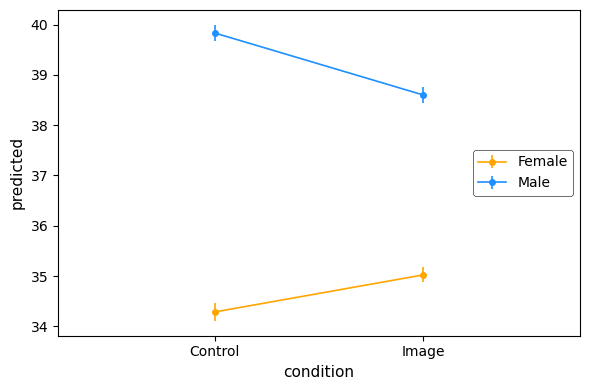

In [221]:
fig, ax = plt.subplots(figsize=(6, 4))

colors = {"Female": "orange", "Male": "dodgerblue"}
xpos = {"Control": 0.42, "Image": 0.58}

for g in ["Female", "Male"]:
    d = plot_df[plot_df["gender"] == g].copy()
    d["x"] = d["condition"].map(xpos)
    d = d.sort_values("x")

    ax.errorbar(
        d["x"],
        d["age_pred_mean"],
        yerr=d["age_pred_se"],
        color=colors[g],
        marker="o",
        linewidth=1.2,
        markersize=4,
        capsize=0,
        label=g
    )

fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)

ax.set_xlim(0.30, 0.70)
ax.set_xticks([xpos["Control"], xpos["Image"]])
ax.set_xticklabels(["Control", "Image"], color="black", fontsize=10)
ax.set_xlabel("condition", color="black", fontsize=11)
ax.set_ylabel("predicted", color="black", fontsize=11)
ax.tick_params(axis="x", colors="black", labelsize=10)
ax.tick_params(axis="y", colors="black", labelsize=10)

leg = ax.legend(loc="center right", frameon=True, facecolor="white", edgecolor="black")
for txt in leg.get_texts():
    txt.set_color("black")

plt.tight_layout()
plt.show()

Για να ερμηνεύσουμε τα αποτελέσματα, πρέπει πρώτα να βρεθούν οι τιμές των τεσσάρων σημείων:

In [222]:
plot_df[["condition", "gender", "age_pred_mean", "age_pred_se"]]

,condition,gender,age_pred_mean,age_pred_se
0,Control,Female,34.286134,0.177657
1,Control,Male,39.832903,0.162167
2,Image,Female,35.024128,0.148557
3,Image,Male,38.599109,0.153704


Ερμηνεία αποτελεσμάτων πρώτου διαγράμματος:

Το διάγραμμα παρουσιάζει πως και στις δύο συνθήκες του πειράματος η ηλικία των ανδρών είναι αρκετά υψηλότερη από των γυναικών. Στην ομάδα ελέγχου (control) οι άνδρες έχουν προβλεπόμενη ηλικία περίπου 39.83 έτη, ενώ οι γυναίκες 34.2 έτη, κάτι που σημαίνει ότι υπάρχει μια σημαντική διαφορά περίπου 5.6 ετών. Από την άλλη, στην ομάδα εικόνας (image) οι προβλεπόμενες τιμές είναι 38.59 και 35.02 για τους άνδρες και τις γυναίκες αντίστοιχα, οπότε υπάρχει μείωση της διαφορά στα 3.57 περίπου έτη.

Ταυτόχρονα, φαίνεται πως η ηλικία των ανδρών από τη συνθήκη ελέγχου στη συνθήκη εικόνας μειώνεται κατά 1.24 έτη, ενώ αντιθέτως των γυναικών αυξάνεται κατά 0.74 έτη, κατι που μείωνει ελαφρώς το χάσμα μεταξύ των δύο φύλων.

Τέλος, οι ράβδοι σφάλματος παρουσιάζονται ως αρκετά μικρές και για τις τέσσερις τιμές, κάτι που υποδηλώνει πως οι μέσες τιμές των προβλέψεων είναι σχετικά σταθερές. Είναι σημαντικό να επισημανθεί πως οι τιμές του διαγράμματος προκύπτουν από το βασικό μοντέλο πρόβλεψης, το οποίο βασίζεται μόνο στην κατηγορία επαγγέλματος και στον συμμετέχοντα. Δηλαδή, πριν ακόμα εξεταστεί η επίδραση της έκθεσης σε εικόνες, το μοντέλο ήδη αποδίδει υψηλότερα επίπεδα ηλικίας στους άνδρες από τις γυναίκες.

#### Διάγραμμα καταλοίπων

Στο δεύτερο διάγραμμα εμφανίζονται τα κατάλοιπα, δηλαδή η διαφορά μεταξύ της προβλεπόμενης τιμής από το βασικό μοντέλο και της πραγματικής εκτίμησης ηλικίας από τους συμμετέχοντες. Αναλυτικότερα, δημιουργείται ένα διάγραμμα όπου για κάθε συνδυασμό συνθήκης (control/ image) και φύλου υπολογίζεται ο μέσος όρος των καταλοίπων (res_mean) και το αντίστοιχο τυπικό σφάλμα (res_se), τα οποία αποτυπώνονται στο γράφημα με σημεία και ράβδους σφάλματος.
Οι τιμές τοποθετούνται σε συγκεκριμένες θέσεις στον οριζόντιο άξονα ώστε να διαχωρίζονται οπτικά οι δύο συνθήκες του πειράματος, ενώ διαφορετικά χρώματα (πορτοκαλι/ μπλε) χρησιμοποιούνται για τη διάκριση μεταξύ γυναικών και ανδρών. Η μορφοποίηση του διαγράμματος παραμένει ίδια με το προηγούμενο για να είναι εύκολη η σύγκριση των αποτελεσμάτων.

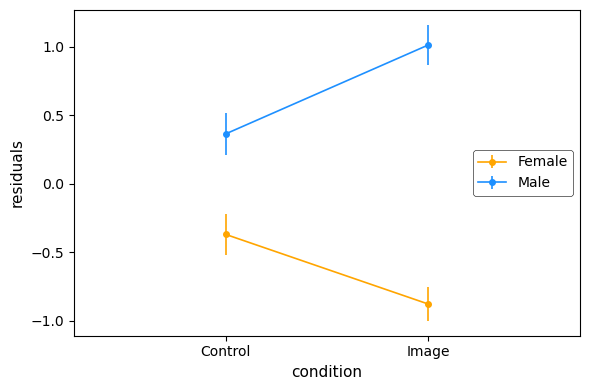

In [223]:
fig, ax = plt.subplots(figsize=(6, 4))

colors = {"Female": "orange", "Male": "dodgerblue"}
xpos = {"Control": 0.42, "Image": 0.58}

for g in ["Female", "Male"]:
    d = plot_df[plot_df["gender"] == g].copy()
    d["x"] = d["condition"].map(xpos)
    d = d.sort_values("x")

    ax.errorbar(
        d["x"],
        d["res_mean"],
        yerr=d["res_se"],
        color=colors[g],
        marker="o",
        linewidth=1.2,
        markersize=4,
        capsize=0,
        label=g
    )

fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)

ax.set_xlim(0.30, 0.70)
ax.set_xticks([xpos["Control"], xpos["Image"]])
ax.set_xticklabels(["Control", "Image"], color="black", fontsize=10)
ax.set_xlabel("condition", color="black", fontsize=11)
ax.set_ylabel("residuals", color="black", fontsize=11)
ax.tick_params(axis="x", colors="black", labelsize=10)
ax.tick_params(axis="y", colors="black", labelsize=10)

leg = ax.legend(loc="center right", frameon=True, facecolor="white", edgecolor="black")
for txt in leg.get_texts():
    txt.set_color("black")

plt.tight_layout()
plt.show()

Για να ερμηνεύσουμε τα αποτελέσματα βρίσκουμε τις τιμές των τεσσάρων σημείων του διαγράμματος:

In [224]:
res_table = plot_df.copy()
res_table["res_mean"] = res_table["res_mean"]
res_table["res_se"] = res_table["res_se"]

res_table[["condition", "gender", "res_mean", "res_se"]]

,condition,gender,res_mean,res_se
0,Control,Female,-0.368949,0.149314
1,Control,Male,0.365164,0.154462
2,Image,Female,-0.876526,0.123249
3,Image,Male,1.013092,0.147402


Ερμηνεία αποτελεσμάτων δεύτερου διαγράμματος:

Στην ομάδα ελέγχου (control) οι άνδρες έχουν θετικό μέσο όρο καταλοίπων (0.36) ενώ οι γυναίκες αρνητικό (-0.37). Αυτό σημαίνει πως οι άντρες εκτιμούνται ως ελαφρώς μεγαλύτεροι και οι γυναίκες ως νεότερες. Συγκεκριμένα, η διαφορά ανάμεσα στα δύο φύλα είναι 0.73 έτη.

Στην ομάδα εικόνας (image) παρουσιάζεται εντονότερη απόκλιση ανάμεσα στα δύο φύλα, καθώς οι άντρες εκτιμώνται ακόμα πιο μεγαλύτεροι (1.01) και οι γυναίκες ακόμα πιο νεότερες (-0.87). Αυτό καθιστά τη διαφορά παραπάνω από διπλάσια σε σχέση με την ομάδα ελέγχου, στα 1.88 περίπου έτη.

Οι ράβδοι σφάλματος είναι ελαφρώς αυξημένες σε μέγεθος σε σχέση με το προηγούμενο διάγραμμα, κάτι που δείχνει ότι υπάρχει μεγαλύτερη αβεβαιότητα γύρω από τους μέσους όρους των καταλοίπων. Αυτό συμβαίνει επειδή τα κατάλοιπα δείχνουν πόσο απέχουν οι πραγματικές τιμές από αυτές που προβλέπει το μοντέλο, οπότε περιλαμβάνουν όλες τις διαφορές που το μοντέλο δεν έχει καταφέρει να εξηγήσει. Ωστόσο, το μέγεθός τους παραμένει περιορισμένο, δείχνοντας ότι οι μέσες διαφορές μεταξύ των ομάδων εμφανίζονται σχετικά σταθερές.

Συμπερασματικά, τα αποτελέσματα του διαγράμματος προσφέρουν μια ξεκάθαρη εικόνα σχετικά με το φαινόμενο ενίσχυσης της μεροληψίας. Παρ' όλο που στην ομάδα ελέγχου παρατηρείται ήδη μια συστηματική υποεκτίμηση της ηλικίας των γυναικών και υπερεκτίμηση της ηλικίας των ανδρών, η έκθεση στις εικόνες της Google Images δεν αναπαράγει απλώς αυτή τη διαφορά, αλλά τη μεγεθύνει δραματικά. Οπότε οι εικόνες λειτουργούν ενισχυτικά ως προς τις υπάρχουσες προκαταλήψεις, αντί να τις εξομαλύνουν.

## Ανάλυση Διακύμανσης (ANOVA)

Τέλος, κατασκευάζονται δύο μοντέλα ανάλυσης διακύμανσης (ANOVA) με εξαρτημένη μεταβλητή την εκτιμώμενη ηλικία και στα δύο. Τα μοντέλα θα βοηθήσουν στη εξέταση του κατά πόσο η πειραματική συνθήκη (ομάδα ελέγχου/ εικόνας) και το φύλο επηρεάζουν στατιστικά σημαντικά την εκτίμηση της ηλικίας, καθώς και του αν υπάρχει μεταξύ τους αλληλεπίδραση. Χρησιμοποιείται αθροιστική κωδικοποίηση (Sum encoding), και άρα κάθε κατηγορία συγκρίνεται με τον συνολικό μέσο όρο. Το πρώτο μοντέλο περιλαμβάνει μόνο τη συνθήκη και το φύλο, ενώ το δεύτερο περιλαμβάνει επίσης και το επάγγελμα και τον συμμετέχοντα ως πρόσθετες μεταβλητές. Έτσι, μπορεί να απομονωθεί η επίδραση τους και να εξεταστεί αν θα υπάρξει κάποια αλλαγή στα αποτελέσματα.

Αρχικά, ορίζεται το πρώτο μοντέλο με εξαρτημένη μεταβλητή την ηλικία (age) και ανεξάρτητες μεταβλητές τη συνθήκη (condition) και το φύλο (gender) με αθροιστική κωδικοποίηση (Sum), καθώς και την αλληλεπίδρασή τους. Το μοντέλο εκτελείται με OLS στο σύνολο των δεδομένων 'df_together' που περιέχει όλες τις παρατηρήσεις από τις δύο πειραματικές συνθήκες. Με τη συνάρτηση 'anova_lm' εξάγεται ο πίνακας ανάλυσης διακύμανσης τύπου 2 (typ=2) και αποθηκεύεται στη μεταβλητή 'table_1'.

In [225]:
model_1 = smf.ols("age ~ C(condition, Sum) * C(gender, Sum)", data=df_together).fit()

table_1 = sm.stats.anova_lm(model_1, typ=2)
table_1

,sum_sq,df,F,PR(>F)
"C(condition, Sum)",57.586138,1.0,0.607880,4.356088e-01
"C(gender, Sum)",71856.913990,1.0,758.522619,5.017108e-160
"C(condition, Sum):C(gender, Sum)",347.367889,1.0,3.666820,5.553946e-02
Residual,806175.481608,8510.0,NaN,NaN


Παρομοίως, ορίζεται το δεύτερο μοντέλο με εξαρτημένη μεταβλητή την ηλικία (age) και ανεξάρτητες μεταβλητές τη συνθήκη (condition) και το φύλο (gender) με αθροιστική κωδικοποίηση (Sum), καθώς και την αλληλεπίδρασή τους, ενώ επιπλέον προστίθενται η κατηγορία επαγγέλματος (category) και ο συμμετέχων (subj) ως παράγοντες ελέγχου. Το μοντέλο εκτελείται με OLS στο σύνολο των δεδομένων 'df_together'. Με τη συνάρτηση 'anova_lm' εξάγεται ο πίνακας ανάλυσης διακύμανσης τύπου 2 (typ=2) και αποθηκεύεται στη μεταβλητή 'table_2'.

In [226]:
model_2 = smf.ols("age ~ C(condition, Sum) * C(gender, Sum) + C(category) + C(subj)", data=df_together).fit()

table_2 = sm.stats.anova_lm(model_2, typ=2)
table_2

,sum_sq,df,F,PR(>F)
"C(condition, Sum)",620.352248,1.0,13.649851,2.217273e-04
"C(gender, Sum)",8055.025507,1.0,177.237846,5.166031e-40
C(category),230669.638586,53.0,95.764404,0.000000e+00
C(subj),456023.489314,453.0,22.150246,0.000000e+00
"C(condition, Sum):C(gender, Sum)",329.073698,1.0,7.240736,7.141576e-03
Residual,363807.622227,8005.0,NaN,NaN


#### Ερμηνεία των αποτελεσμάτων των αναλύσων ANOVA:

Πρώτο μοντέλο (δε περιλαμβάνει έλεγχο για επάγγελμα και συμμετέχοντα):

C(condition) -> Η συνθήκη του πειράματος φαίνεται να μη παρουσιάζει στατιστικά σημαντική επίδραση (F = 0.608, p = 0.436), κάτι που σημαίνει ότι δεν παρατηρείται ουσιαστική διαφορά στις εκτιμήσεις ηλικίας μεταξύ της ομάδας ελέγχου και της ομάδας εικόνας σε αυτό το μοντέλο.

C(gender) -> Αντίθετα, το φύλο παρουσιάζει εξαιρετικά ισχυρή και στατιστικά σημαντική επίδραση (F = 758.52, p < 0.001). Αυτό δείχνει ότι το φύλο επηρεάζει πάρα πολύ την εκτίμηση της της ηλικίας.

C(condition):C(gender) -> Η αλληλεπίδραση μεταξύ συνθήκης και φύλου είναι οριακή (F = 3.67, p = 0.0555 (>0.05)), και άρα μπορεί να υπάρχει διαφοροποίηση στην επίδραση της πειραματικής συνθήκης μεταξύ ανδρών και γυναικών, αλλά δεν υπάρχουν αρκετές αποδείξεις ώστε να θεωρηθεί αυτη η διαφοροποίηση στατιστικά σημαντική.


Δεύτερο μοντέλο (περιλαμβάνει έλεγχο για επάγγελμα και συμμετέχοντα):

C(condition) -> Με τον έλεγχο των επιδράσεων του επαγγέλματος και του συμμετέχοντα, η συνθήκη του πειράματος παρουσιάζει πλέον στατιστικά σημαντική επίδραση (F = 13.65, p < 0.001). Οπότε, η έκθεση σε εικόνες επηρεάζει τις εκτιμήσεις της ηλικίας όταν ληφθούν υπόψη και οι υπόλοιποι παράγοντες.

C(gender) -> Το φύλο παραμένει στατιστικά σημαντικό (F = 177.24, p < 0.001). Άρα επαληθεύεται πως οι διαφορές μεταξύ ανδρών και γυναικών είναι σταθερές και δεν οφείλονται σε άλλες μεταβλητές του μοντέλου.

C(category) -> Η κατηγορία επαγγέλματος έχει πολύ σημαντική επίδραση (F = 95.76, p < 0.001). Αυτό σημαίνει πως οι συμμετέχοντες 
αποδίδουν διαφορετικές ηλικίες σε διαφορετικά επαγγέλματα ανεξάρτητα από τη συνθήκη ή το φύλο της εικόνας.

C(subj) -> Παρομοίως, ο συμμετέχων εμφανίζει υψηλή και στατιστικά σημαντική επίδραση (F = 22.15, p < 0.001), κάτι που δηλώνει πως τα άτομα κάνουν με διαφορετικό τρόπο τις εκτιμήσεις των ηλικιών.

C(condition):C(gender) -> Η αλληλεπίδραση μεταξύ συνθήκης και φύλου γίνεται στατιστικά σημαντική σε αυτό το μοντέλο (F = 7.24, p = 0.0071) σε αντίθεση με το πρώτο μοντέλο. Αυτό δείχνει ότι η επίδραση της έκθεσης σε εικόνες διαφέρει μεταξύ ανδρών και γυναικών. Συγκεκριμένα, οι γυναίκες τείνουν να έχουν χαμηλότερες εκτιμήσεις ηλικίας και οι άνδρες υψηλότερες, ενώ η διαφορά αυτή είναι πιο έντονη στην ομάδα εικόνας σε σχέση με την ομάδα ελέγχου.


Συμπερασματικά, η σύγκριση των δύο μοντέλων δείχνει ότι ο έλεγχος για την κατηγορία επαγγέλματος και τον συμμετέχοντα είναι καθοριστικός ώστε να αναδειχθεί το φαινόμενο της ενίσχυσης της στρέβλωσης. Δηλαδή, οι διαφορές μεταξύ επαγγελμάτων και συμμετεχόντων εξηγούν σημαντικό μέρος της συνολικής διακύμανσης και όταν αφαιρεθεί η επίδρασή τους, η αλληλεπίδραση συνθήκης και φύλου γίνεται στατιστικά σημαντική. Αυτό επιβεβαιώνει ότι η έκθεση σε εικόνες από το Google Images σχετίζεται με διαφοροποιήσεις στις εκτιμήσεις ηλικίας μεταξύ ανδρών και γυναικών και έτσι ενισχύονται τα στερεότυπα ηλικίας και φύλου..